# Discovering dynamical systems (SINDy / DAEs)

`jax_ibart.dynamics` applies the same sparse-regression idea to governing
equations (SINDy; Brunton, Proctor & Kutz 2016). For an ODE it regresses each
state's time derivative on a library of candidate terms and keeps only a few.

Here the library is a fixed polynomial basis (degree up to 2), not iBART's
grow-and-prune descriptor search. The package supplies the symbolic bookkeeping,
the l0 best-subset fit and an optional BART screen.

References: see [docs/references.md](../references.md).

## Explicit ODE discovery: the Lorenz system

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from jax_ibart import dynamics

def lorenz(t, s, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = s
    return [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]

t = np.arange(0.0, 20.0, 0.002)
sol = solve_ivp(lorenz, [t[0], t[-1]], [-8, 8, 27], t_eval=t, rtol=1e-9, atol=1e-9)
X = sol.y.T   # (n_time, 3) trajectory
X.shape

(10000, 3)

Derivatives are estimated from the trajectory by finite differences, then each equation is recovered by sparse regression:

In [2]:
system = dynamics.discover_ode(X, t, ["x", "y", "z"], degree=2, max_terms=3)
print(system)
print("\ntrue: dx/dt = 10(y - x);  dy/dt = 28x - y - xz;  dz/dt = xy - 2.667 z")

dx/dt = -9.999*x + 9.999*y - 7.772e-5  (R^2=1.000)
dy/dt = -0.9998*x*z + 27.99*x - 0.9987*y - 0.0001224  (R^2=1.000)
dz/dt = 0.9999*x*y - 2.666*z - 0.0002812  (R^2=1.000)

true: dx/dt = 10(y - x);  dy/dt = 28x - y - xz;  dz/dt = xy - 2.667 z


The Lorenz equations come back with the right terms and coefficients, with
R^2 = 1.0, directly from the trajectory.

### The attractor we learned from

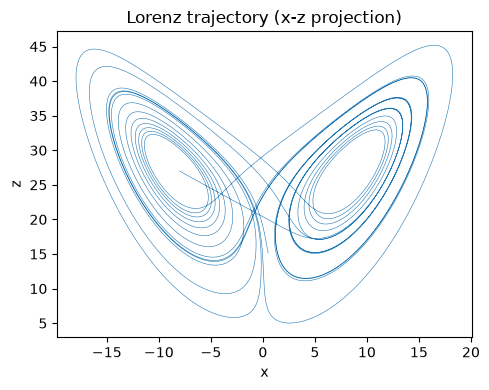

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(X[:, 0], X[:, 2], lw=0.4)
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title("Lorenz trajectory (x-z projection)")
fig.tight_layout(); plt.show()

### How the fit works: derivative parity

SINDy fits each `dx_i/dt` as a sparse linear combination of library terms. The
parity plots below compare the finite-difference derivative (the target) with
the fitted right-hand side, one equation at a time.

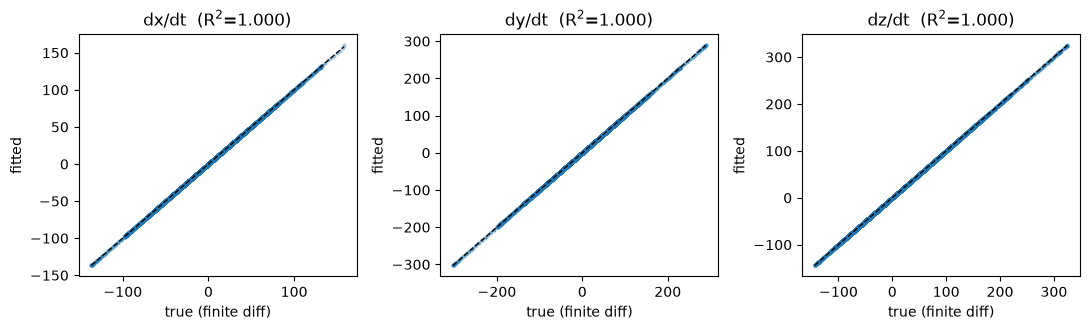

In [4]:
from jax_ibart.dynamics import finite_difference
import sympy as sp

dX = finite_difference(X, t)
syms = sp.symbols("x y z")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    f = sp.lambdify(syms, system.rhs[i], "numpy")
    pred = f(X[:, 0], X[:, 1], X[:, 2])
    ax.scatter(dX[:, i], pred, s=4, alpha=0.3)
    lo, hi = dX[:, i].min(), dX[:, i].max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_title(f"d{name}/dt  (R$^2$={system.r2[i]:.3f})")
    ax.set_xlabel("true (finite diff)"); ax.set_ylabel("fitted")
fig.tight_layout(); plt.show()

### Does the discovered model reproduce the dynamics?

The strongest test is to integrate the *discovered* equations from the same
initial condition and compare with the true trajectory.

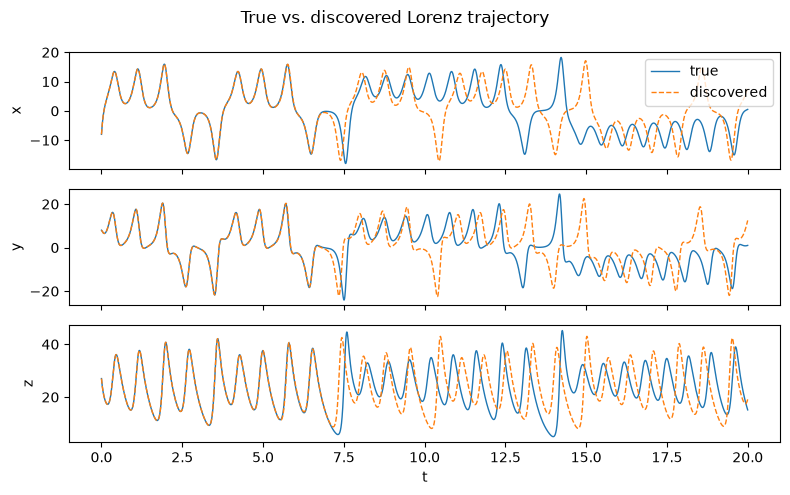

In [5]:
funcs = [sp.lambdify(syms, e, "numpy") for e in system.rhs]
def learned(t, s):
    return [float(f(*s)) for f in funcs]

sol2 = solve_ivp(learned, [t[0], t[-1]], [-8, 8, 27], t_eval=t, rtol=1e-9, atol=1e-9)
Xh = sol2.y.T

fig, axes = plt.subplots(3, 1, figsize=(8, 5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(t, X[:, i], lw=1.0, label="true")
    ax.plot(t, Xh[:, i], "--", lw=1.0, label="discovered")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("t")
fig.suptitle("True vs. discovered Lorenz trajectory")
fig.tight_layout(); plt.show()

The discovered system tracks the true trajectory for several oscillations. The
two eventually separate because Lorenz is chaotic: tiny differences in the
coefficients grow exponentially. That is a property of the system, not an error
in the recovered equations.

## Toward DAEs: implicit algebraic constraints

A differential-algebraic system also has algebraic constraints `0 = g(x, z)`.
Finding those is an *implicit* (null-space) problem, not a regression on a
target, so it needs different machinery. `implicit_constraints` looks for a
combination of library terms that is zero on every sample. Here it recovers
the constraint satisfied by points on a unit circle.

In [6]:
theta = np.linspace(0, 2 * np.pi, 200)
C = np.column_stack([np.cos(theta), np.sin(theta)])   # x^2 + y^2 = 1
res = dynamics.implicit_constraints(C, ["x", "y"], degree=2)
print("constraint ~ 0:", res["constraint"])
print("residual (0 = exact):", round(res["residual"], 6))
print("note:", res["note"])

constraint ~ 0: 1.0*x**2 + 1.0*y**2 - 1.0
residual (0 = exact): 0.0
note: PROTOTYPE: dense SVD null space; production needs sparse null-space selection + weak form (see docstring).


It recovers `x^2 + y^2 - 1 = 0` exactly. A production DAE module would add
sparse null-space selection and a weak (integral) formulation (Mangan et al.
2016; Kaheman et al. 2020; Messenger & Bortz 2021), and would separate
differential from algebraic relations. The descriptor generation, unit filter,
screening and uncertainty tools all carry over.